## Problem Statement
    
### Earthquake
    
    The earth is made of 4 layers inner core, outer core, mantle and crust. The top most is the crust, however this crust and top part of mantle are not completely one sheet warpping the core instead they are more like lego pieces put together. Consequently, these pieces are always at risk of falling apart. In reality, these pieces move around sometimes sliding and bumping into each other. If you've had a geography class back in high school, you must be familiar with the term tectonic plates, they are nothing but the lego pieces we've been talking about. When these plates(pieces) bump into each other they might slip out of place causing imbalance in the surface which is considered an earthquake. This explanation is only an overview of what and how an earthquake takes place, if you're interested check this link out:

https://www.usgs.gov/natural-hazards/earthquake-hazards/science/science-earthquakes?qt-science_center_objects=0#qt-science_center_objects
    
    

### Importance of Forecasting earthquakes
    
    Forecasting earthquakes is one of the most important problems in Earth science. The ability to forecast would help the respective organizations to be better prepared for any of these natural phenomenon. With a good amount of confidence that some disaster could occur, people can be advised beforehand to take proper measures to ensure minimal loss to life and property. It is fairly safe to say(based on history) that these events could be forecasted with probability concepts. In that spirit, we shall use some probability concepts to do our best in forecasting a potential risk of earthquake.
    

### The problem
    
    On a high level, the aim is to identify when an earthquake would take place. At a deeper level, understanding a problem would require knowledge of the premise, what factors might contribute to premise, and the expectation from solution. We know the idea is to forecast a future occurance of earthquake but what factors are we going to use would be clear once we look at the data.

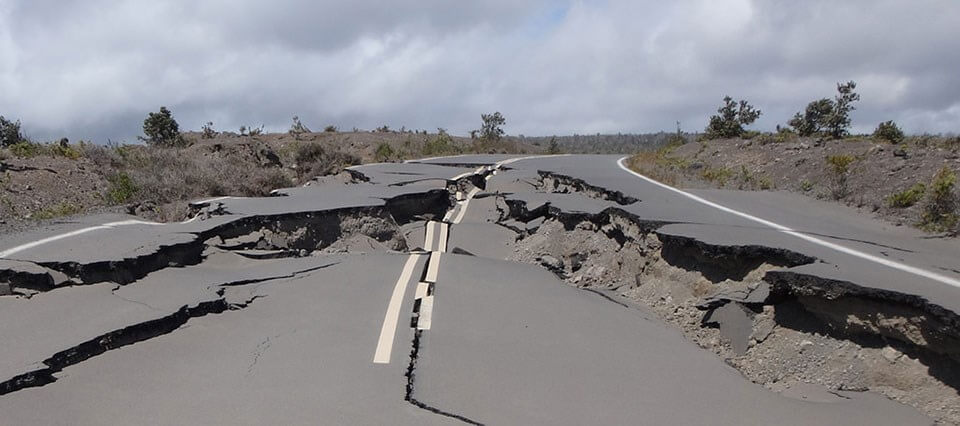

In [1]:
from IPython.display import Image
Image("earthquake.png")


### Importing Dependencies

In [1]:
import time
import glob
import sys
import os
import warnings
warnings.filterwarnings('ignore')
import random
from tqdm import tqdm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import  cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import kurtosis
from scipy.stats import skew
from scipy.stats import norm

from sklearn.model_selection import GridSearchCV
import eli5
from eli5.sklearn import PermutationImportance
import pdpbox


from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRFRegressor
from lightgbm import LGBMRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error

Using TensorFlow backend.


### The test directory

In [2]:
len(os.listdir(os.path.join('LANL-Earthquake-data/test')))

2624

    We have 2624 files in the test directory each belonging to one segment. So, the idea is to predict the time_to_failure for all these segments

    From the test directory, we can realize that the data is segmented and the aim is to predict time-to-failure for each segment. The train dataset on the other hand isn't divided into segments, it's provided more like a single continous segment. Consider it a segment or not the goal remains same, but since the test set is segmented we shall do the same to train.
    
    Let's randomly generate segments of 100000 rows each.


### Exploratory Data Analysis(EDA) 

    The directory for this project is full of data. We have a predetrmined split of train and test data inside the "LANL-Earthquake-data" folder. Let's load the train data

In [3]:
train = pd.read_csv('LANL-Earthquake-data/train.csv')
train.head()

,acoustic_data,time_to_failure
0,12,1.4691
1,6,1.4691
2,8,1.4691
3,5,1.4691
4,8,1.4691


    It took quite a while to load the data, aproxmately some 2.5-3min. Let's have a look at the specifics of the file(#datapoints, columns) to realize how huge the source is and then the actual size of data.

In [4]:
print(f'Rows: {train.shape[0]}')
print(f'Columns: {train.shape[1]}')

Rows: 629145480
Columns: 2


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629145480 entries, 0 to 629145479
Data columns (total 2 columns):
acoustic_data      int64
time_to_failure    float64
dtypes: float64(1), int64(1)
memory usage: 9.4 GB


    The memory currently being used is 9.4GB, this is a little too much for a local PC. One handy way to get around this trouble is identifying how big any given value in a column would get and then change the type from int64 or float64 to int32 or 16 or even 8.

In [6]:
%%time
print(f'Max_value: ',max(train['acoustic_data']))
print(f'Min_value: ',min(train['acoustic_data']))

Max_value:  5444
Min_value:  -5515
Wall time: 1min 49s


In [7]:
%%time
print(f'Max_value: ',max(train['time_to_failure']))
print(f'Min_value: ',min(train['time_to_failure']))

Max_value:  16.1074
Min_value:  9.550396316600001e-05
Wall time: 2min 7s


    We now have a proof that the range of int64/float64 is too huge for data we have and the simple calculation of max itself took a while, imagine if we have to do some complex calculation. I wouldn't be surprised if it takes several minutes or even hours.
    
    One problem at a time, to address the size issue we shall now reduce the range of int and float to 16 and 32 respectively.

In [8]:
train['acoustic_data'] = train['acoustic_data'].astype('int16')
train['time_to_failure'] = train['time_to_failure'].astype('float32')

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629145480 entries, 0 to 629145479
Data columns (total 2 columns):
acoustic_data      int16
time_to_failure    float32
dtypes: float32(1), int16(1)
memory usage: 3.5 GB


    There we have it, we've successfully reduced the memory consumption by almost 6GB.

In [10]:
train.describe()

,acoustic_data,time_to_failure
count,6.291455e+08,6.291455e+08
mean,4.519468e+00,4.477084e-01
std,1.073571e+01,2.612789e+00
min,-5.515000e+03,9.550396e-05
25%,2.000000e+00,2.625997e+00
50%,5.000000e+00,5.349798e+00
75%,7.000000e+00,8.173395e+00
max,5.444000e+03,1.610740e+01


    Like we've seen before the huge size of this data is going to make it a problem for working on whole of the data. For the sake for better processing, quicker results we can start working with 100000 rows

In [11]:
train_org = train.copy(deep=True)

In [12]:
train = train.iloc[:100000,:]

In [13]:
train.shape

(100000, 2)

In [14]:
train.describe()

,acoustic_data,time_to_failure
count,100000.000000,100000.000000
mean,5.015940,1.456352
std,5.680238,0.007503
min,-98.000000,1.443598
25%,3.000000,1.449999
50%,5.000000,1.456399
75%,7.000000,1.462800
max,104.000000,1.469100


Because the size of the database is very large, we shall only look at a part of data for faster processing

In [15]:
train.isna().sum()

acoustic_data      0
time_to_failure    0
dtype: int64

    Acoustic_data simply means the signal on the equipment

In [16]:
train['acoustic_data'].value_counts()

 5     11157
 6     10796
 4     10602
 3      9354
 7      9211
       ...  
 72        1
-56        1
 71        1
 93        1
-81        1
Name: acoustic_data, Length: 158, dtype: int64

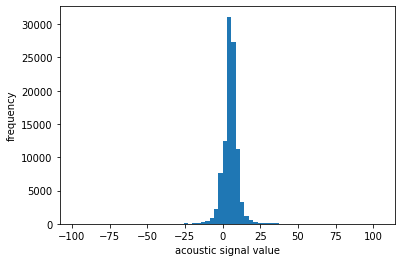

In [17]:
plt.hist(train['acoustic_data'],bins=70)
plt.xlabel('acoustic signal value')
plt.ylabel('frequency')
plt.show()

    Though the signals have occassional high and low values, collection is well centered somewhere around 1-5. We shall anyway confirm this assumption by plotting distribution

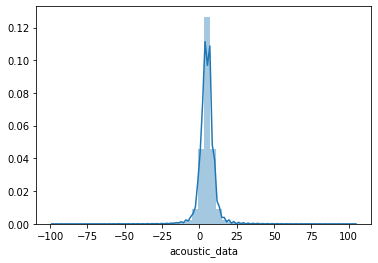

In [18]:
sns.distplot(train["acoustic_data"])
plt.show()

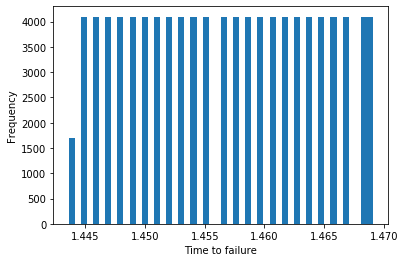

In [19]:
plt.hist(train['time_to_failure'],bins=50)
plt.xlabel('Time to failure')
plt.ylabel('Frequency')
plt.show()

    There's a pretty small range for time_to_failure and hence looking at it by itself doesn't provide us with much of information. Let's look at it in relation to the acoustic signal, we can start off by looking at linear relation if any

Text(0, 0.5, 'Time to failure')

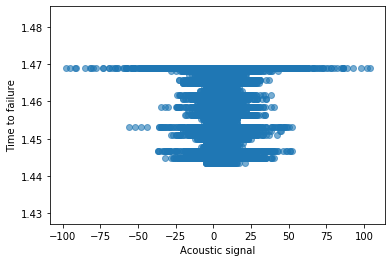

In [20]:
plt.scatter(train['acoustic_data'],train['time_to_failure'],alpha=0.6)
plt.xlabel('Acoustic signal')
plt.ylabel('Time to failure')

    There's no discernable pattern except for the fact that highest time-to-failure occured at broadest of signals. This doesn't necessarily mean that they are linearly related. We can also represent the same relation with a barplot in the spirit of identifying any pattern.

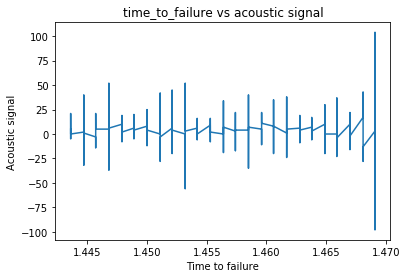

In [21]:
plt.plot(train["time_to_failure"], train["acoustic_data"])
plt.title("time_to_failure vs acoustic signal")
plt.xlabel('Time to failure')
plt.ylabel('Acoustic signal')
plt.show()

    However, we can apply the correlation function to see if there's some relation 

In [22]:
train.corr()

,acoustic_data,time_to_failure
acoustic_data,1.000000,-0.008397
time_to_failure,-0.008397,1.000000


    Like we've suspected and noticed from the charts above, there's close to no linear relationship between the variables

### The benchmark

    We know our target is a numerical feature, so we are going to use regression techniques. However, we can't directly jump into building models. We have, in the beginning decided that predictions are to be done by segment. Let's segment our training data now

In [23]:
rows = 100000
segments = np.floor(train_org.shape[0] / rows)
segments

6291.0

    So, the data is now segmented into 6291 parts, we might want to convert that number to an integer. Now, since the data is segmented, we can't directly use the numbers as is instead will have to use some aggregated metrics to represent respective segments.
    
    As a start we can use mean, median, mode, skew, kurtosis, variance, standard deviation, IQR, sum

In [24]:
segments = int(segments)
X_train = pd.DataFrame(index=range(segments), dtype=np.float64,
                       columns=['mean_', 'median_', 'mode_', 'std_', 'var_', 'max_', 'min_','sum_','skew_','kurt'])
y_train = pd.DataFrame(index=range(segments), dtype=np.float64,
                       columns=['time_to_failure'])

    Now, the placeholders for train and test data are created. It's time to get to actual calculation of all the aforementioned metrics.
    Before we go ahead, for features we shall use aggregated metrics what about target?
---

    We can still use the average or if the entries are temporal simply the last entry could represent progress till then in any given segment

In [25]:
for segment in tqdm(range(segments)):
    start = segment*rows
    end = (segment*rows)+rows
    data = train_org.iloc[start:end]
    signal = data['acoustic_data'].values
    output = data['time_to_failure'].values[-1]
    
    y_train.loc[segment, 'time_to_failure'] = output
    X_train.loc[segment, 'mean_'] = np.mean(signal)
    X_train.loc[segment, 'median_'] = np.median(signal)
    X_train.loc[segment, 'mode_'] = pd.value_counts(signal).keys()[0]
    X_train.loc[segment, 'std_'] = np.std(signal)
    X_train.loc[segment, 'var_'] = np.var(signal)
    X_train.loc[segment, 'max_'] = np.max(signal)
    X_train.loc[segment, 'min_'] = np.min(signal)
    X_train.loc[segment, 'sum_'] = np.sum(signal)
    X_train.loc[segment, 'skew_'] = skew(signal)
    X_train.loc[segment, 'kurt'] = kurtosis(signal)
    

100%|█████████████████████████████████████████████████████████████████████████████| 6291/6291 [00:47<00:00, 131.52it/s]


In [26]:
X_train.head()

,mean_,median_,mode_,std_,var_,max_,min_,sum_,skew_,kurt
0,5.01594,5.0,5.0,5.680210,32.264786,104.0,-98.0,501594.0,-0.071023,32.336677
1,4.65943,5.0,5.0,5.779182,33.398942,181.0,-154.0,465943.0,0.496246,116.642329
2,4.73945,5.0,5.0,6.199615,38.435224,152.0,-150.0,473945.0,0.316915,101.698287
3,4.81588,5.0,5.0,5.981707,35.780820,97.0,-87.0,481588.0,-0.114993,22.802360
4,4.96553,5.0,5.0,7.515485,56.482522,140.0,-106.0,496553.0,0.410932,31.884058


In [27]:
y_train.head()

,time_to_failure
0,1.443598
1,1.418096
2,1.391499
3,1.365897
4,1.339300


In [28]:
X_train.isna().sum()

mean_      0
median_    0
mode_      0
std_       0
var_       0
max_       0
min_       0
sum_       0
skew_      0
kurt       0
dtype: int64

In [29]:
lin_reg = LinearRegression()
lin_reg.fit(X_train,y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [30]:
pred = lin_reg.predict(X_train)

    This problem is originally derived from kaggle competetion and in that competition metric in use was mean_absolute_error. So, we shall also use the same

In [31]:
slr_mae = mean_absolute_error(pred,y_train)

In [32]:
results = pd.DataFrame(columns=['Process','Mean_absolute_error'])
results.loc[len(results)] = ['Simple Linear Regression',slr_mae]

    The target now is to improve the mean_absolute_error from 2.65. We can employ different methods to improve performance:
    - Use complex algorithms
    - cross-validation
    - Hyperparameter tuning
    
    To make this process efficient we can build pipelines

    Like it's said earlier, the problem is derived from a kaggle competition. So the test set doesn't have any labels for verification and hence we'll have to make do with the existing data.

In [34]:
class calcualte_agg_metrics(BaseEstimator,TransformerMixin):
    def __init__(self,rows):
        self.rows = rows
        
    def fit(self,X,y=None):
        self.segments = int(len(X)/self.rows)
        self.X_ = pd.DataFrame(index=range(self.segments), dtype=np.float64,)
        
        return self
    
    
    def transform(self,X,y=None):
        for segment in tqdm(range(self.segments)):
            start = segment*rows
            end = (segment*rows)+rows
            signal = X.iloc[start:end].values
            
            self.X_.loc[segment, 'mean_'] = np.mean(signal)
            self.X_.loc[segment, 'median_'] = np.median(signal)
            self.X_.loc[segment, 'mode_'] = pd.value_counts(signal).keys()[0]
            self.X_.loc[segment, 'std_'] = np.std(signal)
            self.X_.loc[segment, 'var_'] = np.var(signal)
            self.X_.loc[segment, 'max_'] = np.max(signal)
            self.X_.loc[segment, 'min_'] = np.min(signal)
            self.X_.loc[segment, 'sum_'] = np.sum(signal)
            self.X_.loc[segment, 'skew_'] = skew(signal)
            self.X_.loc[segment, 'kurt'] = kurtosis(signal)
            
        return self.X_
    
def calculate_y_train(rows,y):
    segments = int(len(y)/rows)
    y_ = pd.DataFrame()
    for segment in range(segments):
        start = segment*rows
        end = start + rows
        y_.loc[segment,'time_to_failure'] = y[start:end].values[-1]
        
    return y_

In [35]:
cam = calcualte_agg_metrics(rows=100000)
X = cam.fit_transform(train_org['acoustic_data'])
y = calculate_y_train(rows=100000,y=train_org['time_to_failure'])

100%|█████████████████████████████████████████████████████████████████████████████| 6291/6291 [00:43<00:00, 144.84it/s]


In [36]:
train_len_end = (len(X)*80)/100
test_len_start = train_len_end
X_train,y_train = X.loc[0:train_len_end,:],y.loc[0:train_len_end,:]
X_test,y_test = X.loc[train_len_end:],y.loc[train_len_end:]

    We will now create a series of events through which our data has to pass to finally provide the prediction. We call these series of steps, pipelines.

In [37]:
#let's store the results in a dataframe "results"
results = pd.DataFrame(columns=['method','mean_abs_error'])

#Linear Regression pipeline without cross_validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('Linear Regression',LinearRegression())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

lr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['LR pipeline without cross val',lr_pipe_no_cross_val]



#Support Vector Regressor without cross_Validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('support vector regressor',SVR())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

svr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['SVR pipeline without cross val',svr_pipe_no_cross_val]



#DecisionTreeRegressor without cross_Validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('decision tree regressor',DecisionTreeRegressor())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

dtr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['decisiontree pipeline without cross val',dtr_pipe_no_cross_val]



#RandomForestRegressor without cross_Validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('random forest regressor',RandomForestRegressor())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

rfr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['Random forest without cross val',rfr_pipe_no_cross_val]


#XGBoost Regressor without cross_Validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('XGboost regressor',XGBRFRegressor())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

xgbr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['XGBoost without cross val',xgbr_pipe_no_cross_val]



#LGBMRegressor without cross_Validation and tuning
pipe_no_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('lgbm regressor',LGBMRegressor())])

pipe_no_cross_val.fit(X_train,y_train)
pred_no_cross_val = pipe_no_cross_val.predict(X_test)

lgbmr_pipe_no_cross_val = mean_absolute_error(pred_no_cross_val,y_test)
results.loc[len(results)] = ['LGBM without cross val',svr_pipe_no_cross_val]


In [38]:
results

,method,mean_abs_error
0,LR pipeline without cross val,2.917138
1,SVR pipeline without cross val,2.709549
2,decisiontree pipeline without cross val,3.503971
3,Random forest without cross val,2.769873
4,XGBoost without cross val,2.783151
5,LGBM without cross val,2.709549


### Feature Importance
    
    We shall look at the feture importances from our data in different ways
    
#### Model specific
    RandomForest algorithm by itself has an attribute called feature_importances_ that gives the weights our randomforestregressor had associated with the features.
    We can also infer almost similar information from other algorithms by the co-efficients or weights they associate with variables

In [39]:
rfr = RandomForestRegressor()
rfr.fit(X_train,y_train)

RandomForestRegressor(bootstrap=True, ccp_alpha=0.0, criterion='mse',
                      max_depth=None, max_features='auto', max_leaf_nodes=None,
                      max_samples=None, min_impurity_decrease=0.0,
                      min_impurity_split=None, min_samples_leaf=1,
                      min_samples_split=2, min_weight_fraction_leaf=0.0,
                      n_estimators=100, n_jobs=None, oob_score=False,
                      random_state=None, verbose=0, warm_start=False)

In [40]:
for imp,feat in sorted(zip(rfr.feature_importances_,X_train.columns),reverse=True):
    print(f'{feat}: {imp}')

std_: 0.22853027355827052
var_: 0.2085121430154125
kurt: 0.170990696777037
skew_: 0.0929340943108607
min_: 0.07884490382941861
max_: 0.07710605126410744
mean_: 0.06714938437681794
sum_: 0.06670863370699281
mode_: 0.006685685081087819
median_: 0.0025381340799947084


#### Permutation based(eli5)    
    Using permutation based importances. In this method we pass a fitted model to the permutationimportance function of the eli5 library. This function will consider each column at one time, shuffles the values in it and runs the model as is, if the performance of the model deteriorates then this feature can be considered important

In [41]:
perm = PermutationImportance(rfr, random_state=1).fit(X_test, y_test)
eli5.show_weights(perm,feature_names=X_test.columns.tolist())

Weight,Feature
0.2447 ± 0.0329,kurt
0.1811 ± 0.0256,std_
0.1206 ± 0.0280,var_
0.0338 ± 0.0065,min_
0.0150 ± 0.0059,max_
0.0008 ± 0.0006,median_
-0.0009 ± 0.0020,mode_
-0.0070 ± 0.0043,skew_
-0.0448 ± 0.0100,mean_
-0.0510 ± 0.0142,sum_


    The weight is a pair of numbers first signifying how much the model's performance metric reduced and the second one to what extent was the variation present. This variation is calculated simply by performing multiple random shuffles

#### Partial Dependence Plots
    The major difference between feature_importances and partial dependence plots is that pdps explain how changes in a certain feature for a given datapoint affect the predictions.
    So, instead of shuffling values we would consider a datapoint try predicting target at different values of a given feature

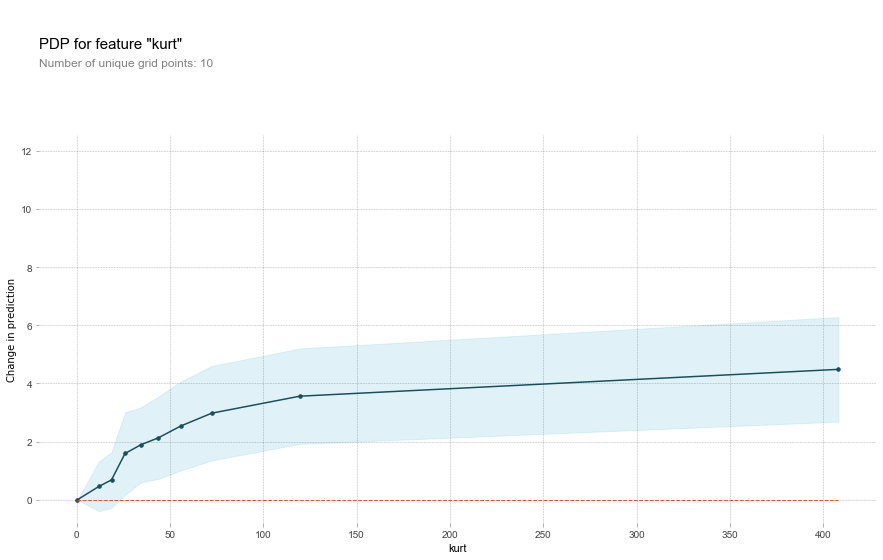

In [42]:
from pdpbox import pdp
pdp_isolate_out = pdp.pdp_isolate(rfr,dataset=X_test,model_features=X_test.columns,feature='kurt')
pdp.pdp_plot(pdp_isolate_out,feature_name='kurt')
plt.ylabel('Change in prediction')
plt.show()

    The way to read this plot is:
    There's a considerable change in prediction when kurt's value is under 100. Once that range is crossed, it pretty much becomes a flat line.
    
    We can also claculate this change in prediction in relation to a pair of variables with the below code. However, there's a bug when using matplotlib version 3.x along with pdp.pdp_interact_plot. So, if you are interested to see how to build those plots, you can use a seperate workspace with matpltolib 2.x. THat being said, you can still run this code and get a plot but we won'be able to infer much without seeing the colorbar that specifies intensity

In [ ]:
pdp_interact_out = pdp.pdp_interact(model=rfr,model_features=X_test.columns,dataset=X_test,features=['std_','kurt'])
pdp.pdp_interact_plot(pdp_interact_out=pdp_interact_out,feature_names=['std_','kurt'],plot_type='contour')
plt.show()

### Using GridSearchCV

In [57]:
grid_lr = GridSearchCV(estimator=LinearRegression(),param_grid={'normalize':[True,False]})
grid_lr.fit(X_train,y_train)

#Linear Regression pipeline with cross_validation and tuning
pipe_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('Linear Regression grid',LinearRegression(**grid_lr.best_estimator_.get_params())
                             )])

pipe_cross_val.fit(X_train,y_train)
pred_cross_val = pipe_cross_val.predict(X_test)

lr_pipe_cross_val = mean_absolute_error(pred_cross_val,y_test)
results.loc[len(results)] = ['LR pipeline with cross val',lr_pipe_cross_val]


#################
grid_svr = GridSearchCV(estimator=SVR(), param_grid={'C':[1,0.01,0.001,0.0001],
                                            'epsilon':[0.5,0.55,0.6]})

grid_svr.fit(X_train,y_train)

#Support Vector Regressor with cross_Validation and tuning
pipe_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('support vector regressor',SVR(**grid_svr.best_estimator_.get_params()))])

pipe_cross_val.fit(X_train,y_train)
pred_cross_val = pipe_cross_val.predict(X_test)

svr_pipe_cross_val = mean_absolute_error(pred_cross_val,y_test)
results.loc[len(results)] = ['SVR pipeline with cross val',svr_pipe_cross_val]


#################
grid_dt = GridSearchCV(estimator = DecisionTreeRegressor(),
                                param_grid = {'max_depth': [4,8,3,10],
                                 'min_samples_split': [2,4]})
grid_dt.fit(X_train,y_train)

#DecisionTreeRegressor with cross_Validation and tuning
pipe_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('decision tree regressor',DecisionTreeRegressor(**grid_dt.best_estimator_.get_params()))])

pipe_cross_val.fit(X_train,y_train)
pred_cross_val = pipe_cross_val.predict(X_test)

dtr_pipe_cross_val = mean_absolute_error(pred_cross_val,y_test)
results.loc[len(results)] = ['DecisionTree pipeline with cross val',dtr_pipe_cross_val]


#################
grid_rf = GridSearchCV(estimator = RandomForestRegressor(),
                                param_grid = {'bootstrap': [True,False],
                                             'min_samples_leaf': [4,7,9],
                                             'n_estimators': [20,30,40,100]
                                             })
grid_rf.fit(X_train[['kurt','std_','var_','min_','max_','median_']],y_train)

#RandomForestRegressor without cross_Validation and tuning
#based on our previous inference about feature importances, we can remove some features
pipe_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('random forest regressor',RandomForestRegressor(**grid_rf.best_estimator_.get_params()))])

pipe_cross_val.fit(X_train[['kurt','std_','var_','min_','max_','median_']],y_train)
pred_cross_val = pipe_cross_val.predict(X_test[['kurt','std_','var_','min_','max_','median_']])

rfr_pipe_cross_val = mean_absolute_error(pred_cross_val,y_test)
results.loc[len(results)] = ['Random forest with cross val',rfr_pipe_cross_val]


##################
grid = GridSearchCV(estimator = XGBRFRegressor(),
                              param_grid = {'n_estimators': [20,30,40,100]
                                            })
grid.fit(X_train,y_train)

#XGBoost Regressor without cross_Validation and tuning
pipe_cross_val = Pipeline([('standard scaler',StandardScaler()),
                             ('XGboost regressor',XGBRFRegressor(**grid.best_estimator_.get_params()))])

pipe_cross_val.fit(X_train,y_train)
pred_cross_val = pipe_cross_val.predict(X_test)

xgbr_pipe_cross_val = mean_absolute_error(pred_cross_val,y_test)
results.loc[len(results)] = ['XGBoost with cross val',xgbr_pipe_cross_val]

In [58]:
results

,method,mean_abs_error
0,LR pipeline without cross val,2.917138
1,SVR pipeline without cross val,2.709549
2,decisiontree pipeline without cross val,3.503971
3,Random forest without cross val,2.769873
4,XGBoost without cross val,2.783151
5,LGBM without cross val,2.709549
6,LR pipeline with cross val,2.917138
7,SVR pipeline with cross val,3.254997
8,DecisionTree pipeline with cross val,2.886097
9,Random forest with cross val,2.574270


In [62]:
def get_stacking():
    #base estimators
    level_0 = list()
    level_0.append(('svr',RandomForestRegressor(**grid_rf.best_estimator_.get_params())))
    level_0.append(('dtc',DecisionTreeRegressor(**grid_dt.best_estimator_.get_params())))
    level_0.append(('xgb',XGBRFRegressor(**grid.best_estimator_.get_params())))
    
    #meta estimator
    level_1 = RandomForestRegressor()
    
    model = StackingRegressor(estimators=level_0, final_estimator=level_1, cv=3)
    
    return model

stack_model = get_stacking()
stack_model.fit(X_train,y_train)
stack_pred = stack_model.predict(X_test)
print(f'Stack_model mean_absolute_error {mean_absolute_error(stack_pred,y_test)}')

Stack_model mean_absolute_error 2.7128836048668825


    We can go ahead with the RandomForestmodel with GridSearch. However, this the best model only based on the experimentation till now we can now look at more hyperparameters for RandomForest and we could hopefully improve the mean_absolute_error. That being said we should attribute this performance a great deal to the features we've created and removed based on feature importance techniques